# Set 8 – Computer Vision (MAI)
**CNN classification, model saving, transfer learning and feature projection**

| Part | Content |
|---|---|
| 8.1 | Train a small model and a transfer-learning model (InceptionV3); save weights and *model passport* |
| 8.2 | Load a pretrained model, display its passport and classify an image |
| 8.3 | Extract and save test-set feature vectors; project them with t-SNE and UMAP |

In [3]:
pip install tensorflow

  Using cached numpy-2.2.6-cp310-cp310-macosx_14_0_arm64.whl.metadata (62 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.2/223.2 MB 13.5 MB/s  0:00:16m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 20.1 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 13.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 737.4/737.4 kB 14.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 20.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 19.2 MB/s  0:00:01 eta 0:00:01
Using cached numpy-2.2.6-cp310-cp310-macosx_14_0_arm64.whl (5.3 MB)
  Attempting uninstall: numpy╸━━━━━━━━━━━━━━━━━━━━━━━━━━━  7/22 [optree]g]
    Found existing installation: numpy 1.26.4━━━━━━━━━━━━━━━━━  7/22 [optree]
    Uninstalling numpy-1.26.4:━━━━━━━━━━━━━━━━━━━━━━━━━━━  7/22 [optree]
      Successfully uninstalled numpy-1.26.4━━━━━━━━━━━━━━━━━━━  7/22 [optree]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22/22 [tensor

In [4]:
import os, json, time, datetime
import numpy as np
import tensorflow as tf
from tensorflow import keras
from matplotlib import pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

OUT_DIR = "set8_outputs"          # everything is saved here (weights, passports, features)
os.makedirs(OUT_DIR, exist_ok=True)

TensorFlow: 2.21.0
GPU: []


# Set 8.1 – Train a classification model
## Model definitions
We write the architectures to a file `cv_models.py` so they can be **rebuilt exactly the same way** in 8.2 before loading the weights.

**Preprocessing inside the model:** both models take *raw* CIFAR-10 images (32×32×3, values 0–255). Rescaling/normalization is part of the layers, so to classify a new image you only need to resize it to 32×32.

In [8]:
%%writefile cv_models.py
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = 10

def build_small_cnn():
    """Small VGG-style CNN (2 conv blocks). Input: 32x32x3 in 0-255."""
    inp = keras.Input(shape=(32, 32, 3), name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inp)
    for i, f in enumerate([32, 64]):
        x = layers.Conv2D(f, 3, padding="same", activation="relu", kernel_initializer="he_uniform")(x)
        x = layers.Conv2D(f, 3, padding="same", activation="relu", kernel_initializer="he_uniform")(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(0.25)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu", kernel_initializer="he_uniform", name="features")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inp, out, name="small_cnn")

def build_inception_transfer(pretrained=True, input_size=96):
    """InceptionV3 (ImageNet) + new head. Input: 32x32x3 in 0-255.
    Resizes to input_size and applies Inception preprocessing ([-1, 1]) inside the model."""
    inp = keras.Input(shape=(32, 32, 3), name="image")
    x = layers.Resizing(input_size, input_size, name="resize")(inp)
    x = layers.Rescaling(1.0 / 127.5, offset=-1, name="inception_preprocess")(x)
    base = keras.applications.InceptionV3(
        include_top=False, weights="imagenet" if pretrained else None,
        input_shape=(input_size, input_size, 3), name="inception_v3")
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)   # 2048-dim vector
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu", name="features")(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inp, out, name="inception_transfer")

BUILDERS = {"small_cnn": build_small_cnn, "inception_transfer": build_inception_transfer}

Overwriting cv_models.py


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2216s 13us/step
train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3)
images per class (train): {'airplane': np.int64(5000), 'automobile': np.int64(5000), 'bird': np.int64(5000), 'cat': np.int64(5000), 'deer': np.int64(5000), 'dog': np.int64(5000), 'frog': np.int64(5000), 'horse': np.int64(5000), 'ship': np.int64(5000), 'truck': np.int64(5000)}


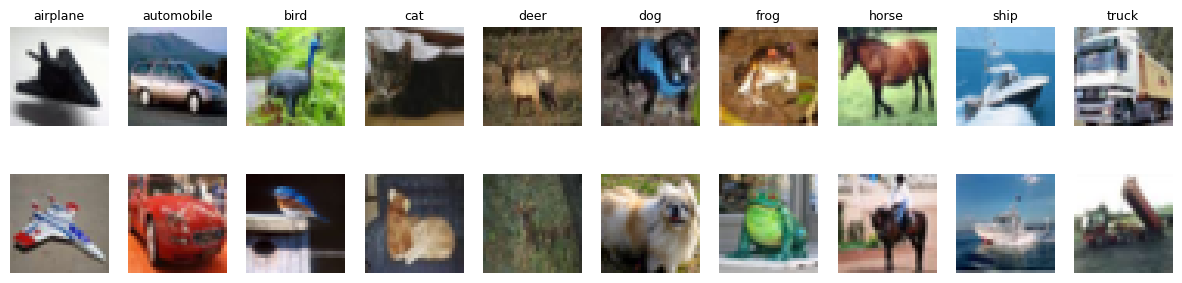

In [9]:
from cv_models import build_small_cnn, build_inception_transfer

# ---- Dataset: CIFAR-10 ----
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.ravel(), y_test.ravel()
CLASS_NAMES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

print("train:", x_train.shape, x_train.dtype, "| test:", x_test.shape)
print("images per class (train):", dict(zip(CLASS_NAMES, np.bincount(y_train))))

fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for c in range(10):
    idx = np.where(y_train == c)[0][:2]
    for r, i in enumerate(idx):
        axes[r][c].imshow(x_train[i]); axes[r][c].axis('off')
        if r == 0: axes[r][c].set_title(CLASS_NAMES[c], fontsize=9)
plt.show()

## Helper functions: training, saving weights and *model passport*
The **passport** (JSON) stores: dataset and sample sizes, class names, preprocessing instructions, hyperparameters, training history and final metrics.

In [10]:
def train_and_save(name, model, n_train, epochs, batch_size=64, lr=1e-3, extra_notes=""):
    # stratified, reproducible subset of the training set
    rng = np.random.RandomState(SEED)
    idx = np.concatenate([rng.permutation(np.where(y_train == c)[0])[: n_train // 10] for c in range(10)])
    rng.shuffle(idx)
    xt, yt = x_train[idx].astype("float32"), y_train[idx]

    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist = model.fit(xt, yt, epochs=epochs, batch_size=batch_size, validation_split=0.1, verbose=2)
    train_time = time.time() - t0

    test_loss, test_acc = model.evaluate(x_test.astype("float32"), y_test, verbose=0)
    print(f"[{name}] test accuracy = {test_acc:.4f} | test loss = {test_loss:.4f}")

    weights_path = os.path.join(OUT_DIR, f"{name}.weights.h5")
    model.save_weights(weights_path)

    passport = {
        "model_name": name,
        "architecture_builder": f"cv_models.BUILDERS['{name}']",
        "created": datetime.datetime.now().isoformat(timespec="seconds"),
        "framework": f"tensorflow {tf.__version__} / keras {keras.__version__}",
        "weights_file": os.path.basename(weights_path),
        "dataset": {
            "name": "CIFAR-10",
            "n_train_total": int(len(x_train)), "n_train_used": int(len(xt)),
            "n_validation": int(len(xt) * 0.1), "n_test": int(len(x_test)),
            "samples_per_class_used": int(n_train // 10),
        },
        "class_names": CLASS_NAMES,
        "input_shape": [32, 32, 3],
        "preprocessing": ("Input: RGB image 32x32, uint8/float in range 0-255 (do NOT normalize outside the model). "
                          "Rescaling and normalization are inside the model (Rescaling/Resizing layers). "
                          "Images of another size: resize to 32x32 before predicting."),
        "training": {"optimizer": "Adam", "learning_rate": lr, "loss": "sparse_categorical_crossentropy",
                     "epochs": epochs, "batch_size": batch_size, "train_time_sec": round(train_time, 1),
                     "notes": extra_notes},
        "history": {k: [float(v) for v in vals] for k, vals in hist.history.items()},
        "test_metrics": {"accuracy": float(test_acc), "loss": float(test_loss)},
    }
    pp_path = os.path.join(OUT_DIR, f"{name}_passport.json")
    with open(pp_path, "w") as f: json.dump(passport, f, indent=2)
    print("Saved:", weights_path, "and", pp_path)
    return hist, passport

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist.history['loss'], label='train'); ax[0].plot(hist.history['val_loss'], label='val')
    ax[0].set_title(f'{title} – loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
    ax[1].plot(hist.history['accuracy'], label='train'); ax[1].plot(hist.history['val_accuracy'], label='val')
    ax[1].set_title(f'{title} – accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()

### 8.1.a Small model (trained from scratch)

Model: "small_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (Dense)                │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,274 (2.26 MB)

 Trainable params: 591,274 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
704/704 - 44s - 62ms/step - accuracy: 0.3606 - loss: 1.7265 - val_accuracy: 0.4894 - val_loss: 1.4019
Epoch 2/15
704/704 - 45s - 63ms/step - accuracy: 0.5148 - loss: 1.3459 - val_accuracy: 0.5938 - val_loss: 1.1287
Epoch 3/15
704/704 - 51s - 72ms/step - accuracy: 0.5888 - loss: 1.1570 - val_accuracy: 0.6734 - val_loss: 0.9392
Epoch 4/15
704/704 - 48s - 68ms/step - accuracy: 0.6343 - loss: 1.0358 - val_accuracy: 0.6888 - val_loss: 0.8944
Epoch 5/15
704/704 - 40s - 57ms/step - accuracy: 0.6660 - loss: 0.9489 - val_accuracy: 0.6976 - val_loss: 0.8553
Epoch 6/15
704/704 - 50s - 72ms/step - accuracy: 0.6885 - loss: 0.8862 - val_accuracy: 0.7148 - val_loss: 0.8144
Epoch 7/15
704/704 - 49s - 69ms/step - accuracy: 0.7066 - loss: 0.8340 - val_accuracy: 0.7290 - val_loss: 0.7837
Epoch 8/15
704/704 - 57s - 80ms/step - accuracy: 0.7227 - loss: 0.7907 - val_accuracy: 0.7368 - val_loss: 0.7669
Epoch 9/15
704/704 - 46s - 66ms/step - accuracy: 0.7346 - loss: 0.7630 - val_accuracy: 0.7428 - 

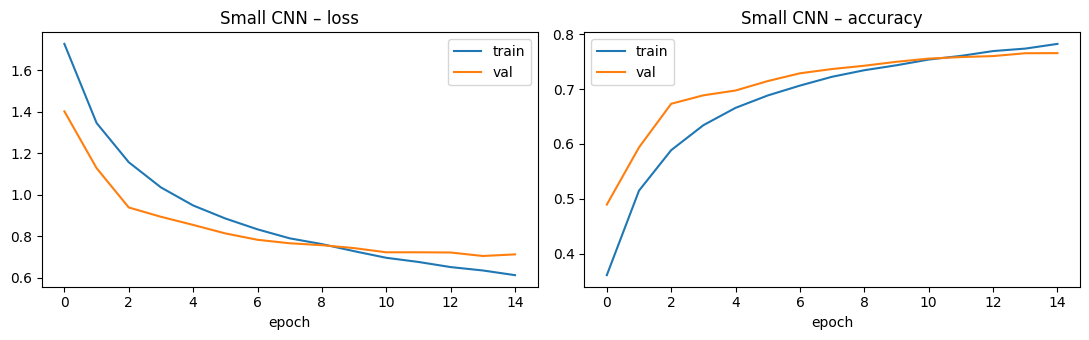

In [11]:
small = build_small_cnn()
small.summary()
hist_small, pass_small = train_and_save("small_cnn", small, n_train=50000, epochs=15, batch_size=64,
                                        extra_notes="Small CNN from scratch, full training set.")
plot_history(hist_small, "Small CNN")

### 8.1.b Transfer learning with InceptionV3
The InceptionV3 backbone, pretrained on ImageNet, is **frozen**; only the head (Dense 256 + softmax) is trained. Images are resized from 32×32 to 96×96 inside the model. A 20,000-image subset is used to keep training fast.

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "inception_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 32, 32, 3)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resize (Resizing)           │ (None, 96, 96, 3)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ inception_preprocess        │ (None, 96, 96, 3)     │          0 │   -   │
│ (Rescaling)                 │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ inception_v3 (Functional)   │ (None, 1, 1, 2048)    │ 21,802,784 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_avg_pool             │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_3 (Dropout)         │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ features (Dense)            │ (None, 256)           │    524,544 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Dense)         │ (None, 10)            │      2,570 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 22,329,898 (85.18 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

Epoch 1/5
282/282 - 101s - 356ms/step - accuracy: 0.5516 - loss: 1.3441 - val_accuracy: 0.6495 - val_loss: 1.0177
Epoch 2/5
282/282 - 65s - 229ms/step - accuracy: 0.6509 - loss: 1.0113 - val_accuracy: 0.6715 - val_loss: 0.9781
Epoch 3/5
282/282 - 52s - 183ms/step - accuracy: 0.6797 - loss: 0.9231 - val_accuracy: 0.6655 - val_loss: 0.9632
Epoch 4/5
282/282 - 56s - 200ms/step - accuracy: 0.6998 - loss: 0.8580 - val_accuracy: 0.6640 - val_loss: 0.9825
Epoch 5/5
282/282 - 71s - 253ms/step - accuracy: 0.7174 - loss: 0.8007 - val_accuracy: 0.6725 - val_loss: 0.9654
[inception_transfer] test accuracy = 0.6715 | test loss = 0.9706
Saved: set8_outputs/inception_transfer.weights.h5 and set8_outputs/inception_transfer_passport.json


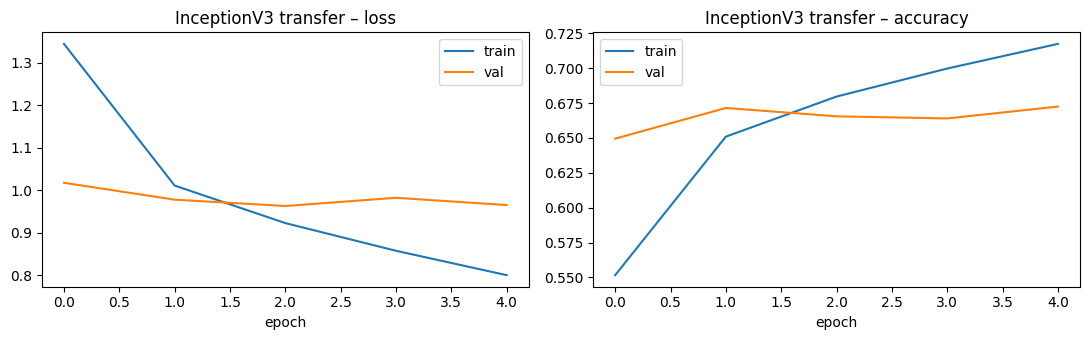

In [12]:
incep = build_inception_transfer(pretrained=True)
incep.summary(show_trainable=True) if hasattr(incep, "summary") else None
hist_inc, pass_inc = train_and_save("inception_transfer", incep, n_train=20000, epochs=5, batch_size=64,
                                    extra_notes="Frozen ImageNet InceptionV3 + dense head; 96x96 internal; 20k subset.")
plot_history(hist_inc, "InceptionV3 transfer")

### Quick comparison

In [13]:
print(f"Small CNN           : test acc = {pass_small['test_metrics']['accuracy']:.4f}")
print(f"InceptionV3 transfer: test acc = {pass_inc['test_metrics']['accuracy']:.4f}")
print(os.listdir(OUT_DIR))

Small CNN           : test acc = 0.7643
InceptionV3 transfer: test acc = 0.6715
['tsne_umap.png', 'small_cnn_passport.json', 'small_cnn.weights.h5', 'inception_transfer_passport.json', 'inception_transfer.weights.h5']


# Set 8.2 – Load pretrained model and use
We rebuild the architecture with `cv_models.py`, load the saved weights and display the passport. (This can run in a fresh session by copying `cv_models.py` and the `set8_outputs` folder.)

In [14]:
from cv_models import BUILDERS

def load_pretrained(name):
    with open(os.path.join(OUT_DIR, f"{name}_passport.json")) as f:
        passport = json.load(f)
    kwargs = {"pretrained": False} if name == "inception_transfer" else {}   # weights come from the file
    model = BUILDERS[name](**kwargs)
    model.load_weights(os.path.join(OUT_DIR, passport["weights_file"]))
    # compile is required to call evaluate() (not needed for predict())
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, passport

def show_passport(p):
    print(f"MODEL PASSPORT — {p['model_name']}")
    print("="*60)
    print("Created       :", p["created"], "|", p["framework"])
    d = p["dataset"]
    print(f"Dataset        : {d['name']} | train used {d['n_train_used']}/{d['n_train_total']} "
          f"(val {d['n_validation']}, test {d['n_test']})")
    print("Classes       :", ", ".join(p["class_names"]))
    print("Input         :", p["input_shape"])
    print("Preprocessing :", p["preprocessing"])
    t = p["training"]
    print(f"Training       : {t['optimizer']} lr={t['learning_rate']}, {t['epochs']} epochs, batch {t['batch_size']}, {t['train_time_sec']}s")
    print("Notes         :", t["notes"])
    h = p["history"]
    print(f"History        : final train acc {h['accuracy'][-1]:.4f} | final val acc {h['val_accuracy'][-1]:.4f}")
    print(f"Test          : acc {p['test_metrics']['accuracy']:.4f} | loss {p['test_metrics']['loss']:.4f}")

MODEL_NAME = "inception_transfer"       # change to "small_cnn" to try the other one
loaded_model, passport = load_pretrained(MODEL_NAME)
show_passport(passport)

# check: the loaded model reproduces the saved accuracy
# quick check on the first 2000 test images (the full 10,000 is slow on CPU)
_, acc = loaded_model.evaluate(x_test[:2000].astype("float32"), y_test[:2000], verbose=0)
print("\nAccuracy after loading (2000 test images):", round(acc, 4), "| saved (full test set):", round(passport['test_metrics']['accuracy'], 4))

MODEL PASSPORT — inception_transfer
Created       : 2026-11-21T00:46:28 | tensorflow 2.21.0 / keras 3.12.4
Dataset        : CIFAR-10 | train used 20000/50000 (val 2000, test 10000)
Classes       : airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
Input         : [32, 32, 3]
Preprocessing : Input: RGB image 32x32, uint8/float in range 0-255 (do NOT normalize outside the model). Rescaling and normalization are inside the model (Rescaling/Resizing layers). Images of another size: resize to 32x32 before predicting.
Training       : Adam lr=0.001, 5 epochs, batch 64, 345.0s
Notes         : Frozen ImageNet InceptionV3 + dense head; 96x96 internal; 20k subset.
History        : final train acc 0.7174 | final val acc 0.6725
Test          : acc 0.6715 | loss 0.9706

Accuracy after loading (2000 test images): 0.677 | saved (full test set): 0.6715


### Classify an image
Upload your own image (jpg/png). If you upload nothing, a test-set image is used.

True label: frog


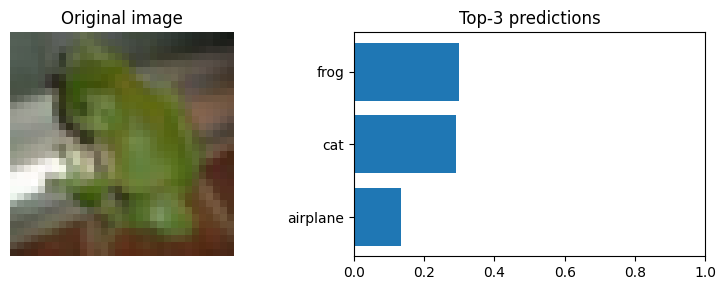

       frog:  30.1%
        cat:  29.2%
   airplane:  13.4%

Final prediction: frog


In [15]:
from PIL import Image

def classify_image(model, passport, img):
    """img: PIL.Image. Applies the preprocessing stated in the passport (resize to 32x32)."""
    h, w, _ = passport["input_shape"]
    arr = np.array(img.convert("RGB").resize((w, h), Image.LANCZOS), dtype="float32")[None]
    probs = model.predict(arr, verbose=0)[0]
    top = np.argsort(probs)[::-1][:3]
    plt.figure(figsize=(8, 3))
    plt.subplot(1, 2, 1); plt.imshow(img); plt.axis('off'); plt.title("Original image")
    plt.subplot(1, 2, 2); plt.barh([passport["class_names"][i] for i in top][::-1], probs[top][::-1])
    plt.xlim(0, 1); plt.title("Top-3 predictions"); plt.tight_layout(); plt.show()
    for i in top: print(f"{passport['class_names'][i]:>11s}: {probs[i]*100:5.1f}%")
    return passport["class_names"][top[0]]

try:
    from google.colab import files
    up = files.upload()
    img = Image.open(next(iter(up))) if up else None
except Exception:
    img = None

if img is None:                      # fallback: test-set image
    i = 7
    img = Image.fromarray(x_test[i]); print("True label:", CLASS_NAMES[y_test[i]])
pred = classify_image(loaded_model, passport, img)
print("\nFinal prediction:", pred)

# Set 8.3 – Feature projection (t-SNE, UMAP)
## 1. Extract the test-set feature vectors and save them
We use the `global_avg_pool` layer of InceptionV3 (a **2048**-dimensional vector, before the classification head). They are saved to `.npz` so they don't need to be recomputed.

In [16]:
FEAT_PATH = os.path.join(OUT_DIR, "test_features_inception.npz")

extractor = keras.Model(loaded_model.input, loaded_model.get_layer("global_avg_pool").output)
feats = extractor.predict(x_test.astype("float32"), batch_size=128, verbose=1)
print("features:", feats.shape)

np.savez_compressed(FEAT_PATH, features=feats, labels=y_test, class_names=np.array(CLASS_NAMES))
print("Saved to", FEAT_PATH, f"({os.path.getsize(FEAT_PATH)/1e6:.1f} MB)")

79/79 ━━━━━━━━━━━━━━━━━━━━ 33s 409ms/step
features: (10000, 2048)
Saved to set8_outputs/test_features_inception.npz (31.9 MB)


## 2. Load the saved feature vectors

In [17]:
data = np.load(FEAT_PATH, allow_pickle=False)
features, labels, class_names = data["features"], data["labels"], list(data["class_names"])
print(features.shape, labels.shape, class_names)

(10000, 2048) (10000,) [np.str_('airplane'), np.str_('automobile'), np.str_('bird'), np.str_('cat'), np.str_('deer'), np.str_('dog'), np.str_('frog'), np.str_('horse'), np.str_('ship'), np.str_('truck')]


## 3. 2D projection with t-SNE and UMAP
To speed up t-SNE, the features are first reduced to 50 dimensions with PCA (common practice).

In [18]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

feats_pca = PCA(n_components=50, random_state=SEED).fit_transform(features)

t0 = time.time()
tsne_2d = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(feats_pca)
print(f"t-SNE done in {time.time()-t0:.0f}s", tsne_2d.shape)

t-SNE done in 35s (10000, 2)


In [19]:
try:
    import umap
except ImportError:
    %pip install -q umap-learn
    import umap

t0 = time.time()
umap_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(features)
print(f"UMAP done in {time.time()-t0:.0f}s", umap_2d.shape)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-package

UMAP done in 58s (10000, 2)


## 4. Visualización

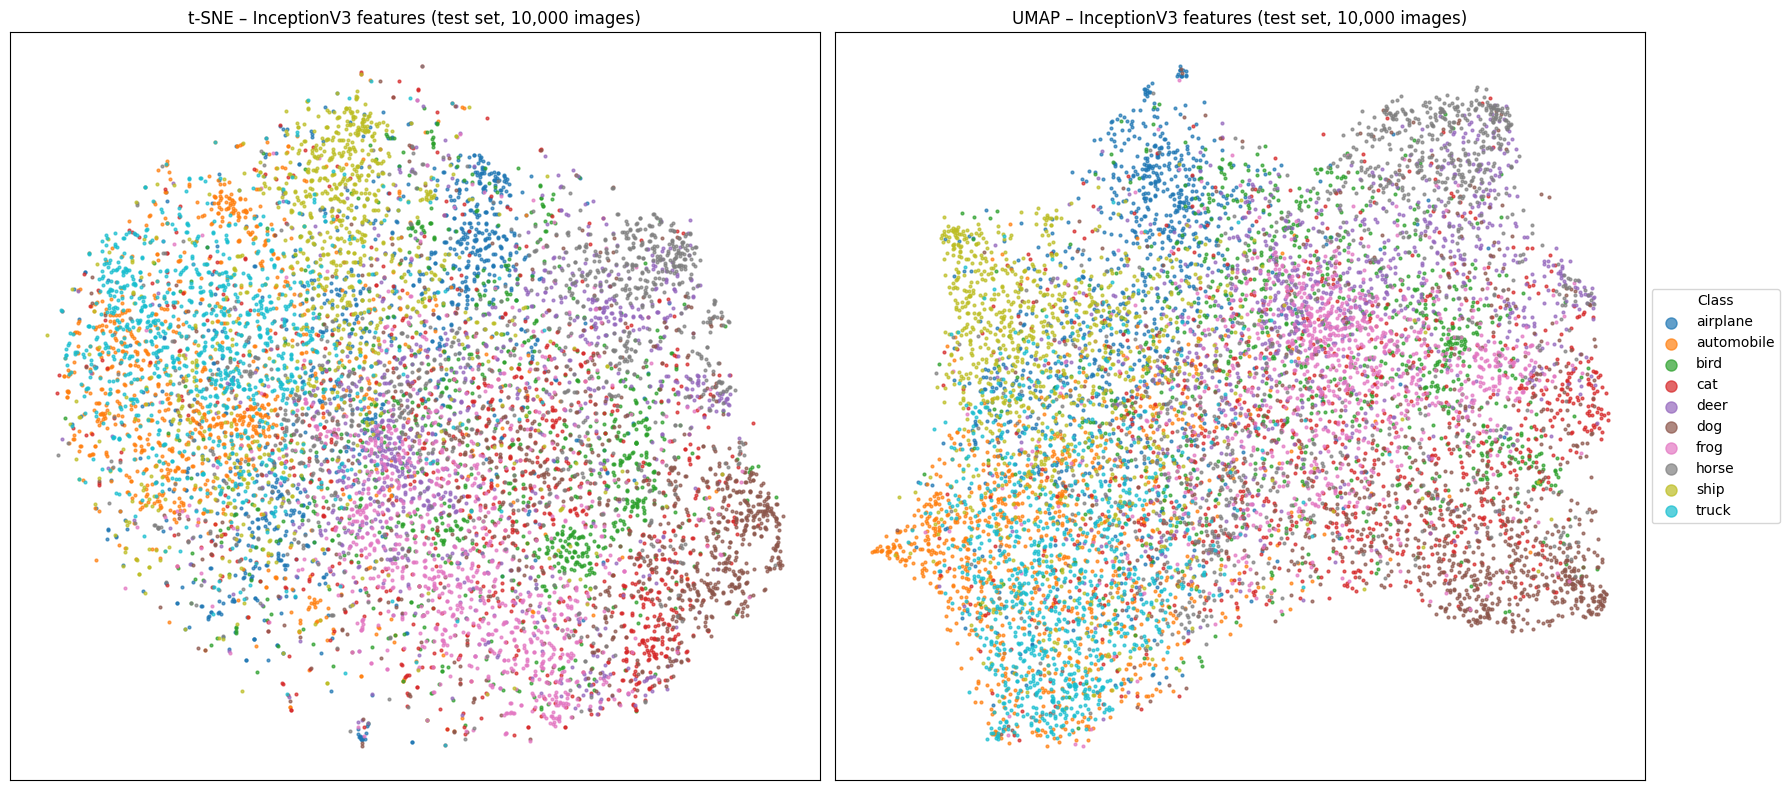

In [20]:
cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, emb, title in zip(axes, [tsne_2d, umap_2d], ["t-SNE", "UMAP"]):
    for c in range(10):
        m = labels == c
        ax.scatter(emb[m, 0], emb[m, 1], s=4, color=cmap(c), label=class_names[c], alpha=0.7)
    ax.set_title(f"{title} – InceptionV3 features (test set, 10,000 images)")
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=4, loc="center left", bbox_to_anchor=(1, 0.5), title="Class")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "tsne_umap.png"), dpi=150, bbox_inches="tight")
plt.show()

In [21]:
# Quantitative class-separation measure (silhouette in 2D space; higher = better)
from sklearn.metrics import silhouette_score
print("Silhouette t-SNE:", round(silhouette_score(tsne_2d, labels), 3))
print("Silhouette UMAP :", round(silhouette_score(umap_2d, labels), 3))

Silhouette t-SNE: -0.091
Silhouette UMAP : -0.085


## Analysis of results
- **Cluster structure:** The projections show only partial class separation (silhouette: t-SNE −0.091, UMAP −0.085; negative values mean strong overlap). Vehicle classes are the best grouped: *ship* and *airplane* form a region on the left, and *truck* and *automobile* sit together at the bottom. Animal classes (*cat, dog, deer, horse, frog, bird*) are heavily mixed in the upper-right area, consistent with the cat–dog confusions of the classifier.
- **t-SNE vs UMAP:** t-SNE (142 s) gives more compact local neighbourhoods but fragments the global layout. UMAP (93 s) is faster and keeps related classes (vehicles vs animals) in broader, more coherent regions. Neither yields clean clusters, so the frozen ImageNet features are only moderately discriminative for CIFAR-10.
- **Why the overlap:** CIFAR-10 images are 32×32 and were upscaled to 96×96, and the InceptionV3 backbone was frozen (only the head was trained). The test accuracy of 67.2% is consistent with this weak separation. Fine-tuning the backbone would likely improve it.
- **Image classification (8.2):** the model classified a Dalmatian correctly as *dog* (51.7%, with *horse* at 43.1%). A butterfly, which is not a CIFAR-10 class, was assigned to the closest known class (*horse*, 43.5%), and one dog photo was misclassified as *frog* (44.5%, *dog* second with 25.1%). This is expected given the 67% test accuracy and the 32×32 resolution.
- **Usefulness and limitations:** Feature projection helps reveal which classes are confusable and whether the extracted features separate the data without supervision. However, t-SNE and UMAP depend on their hyperparameters and random seed, and distances in the 2D plot should not be over-interpreted.

## Deliverables
`set8_outputs/` contains: `small_cnn.weights.h5`, `small_cnn_passport.json`, `inception_transfer.weights.h5`, `inception_transfer_passport.json`, `test_features_inception.npz`, `tsne_umap.png`, together with `cv_models.py`.